
# Obesity Level Prediction Using Machine Learning

**Course:** DS471 – Machine Learning

**Project Objective:** This project aims to predict obesity levels using eating habits and physical characteristics. Three machine-learning models will be developed and compared: Logistic Regression, Random Forest, and a Neural Network.


## Stage 1: Data Cleaning, Preparation and Exploration

### Dataset Description

In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv("/content/ObesityDataSet_raw_and_data_sinthetic.csv")

# Display dataset information
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


### Data Quality Checks

We examine the dataset to identify missing values, duplicate records, inconsistent data, and data types. We also check the distribution of obesity levels before preparing the data for machine learning.

In [2]:
# Check the dataset structure and data types
print("Dataset information:")
df.info()

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicate records
print("\nDuplicate rows:", df.duplicated().sum())

# Check target class distribution
print("\nObesity level distribution:")
print(df["NObeyesdad"].value_counts())

# Check categorical values for inconsistencies
print("\nCategorical feature values:")
for column in df.select_dtypes(include=["object", "category"]).columns:
    print(f"\n{column}:")
    print(df[column].value_counts(dropna=False))

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF          


### Duplicate and Data Consistency Analysis

The dataset contains 24 exact duplicate records and no missing values. Before removing duplicates, we check whether identical feature values have different obesity-level labels.


In [3]:

# Check whether identical features have conflicting labels
feature_columns = df.columns.drop("NObeyesdad")

conflicting_labels = (
    df.groupby(list(feature_columns), dropna=False)["NObeyesdad"]
    .nunique()
)

print("Feature combinations with conflicting labels:",
      (conflicting_labels > 1).sum())

print("Exact duplicate rows:", df.duplicated().sum())


Feature combinations with conflicting labels: 0
Exact duplicate rows: 24



### Duplicate Removal

The dataset contains 24 exact duplicate records. No conflicting class labels were found for identical feature values. Therefore, we remove the duplicate records before splitting the data to prevent repeated observations from affecting model evaluation.


In [4]:

# Remove exact duplicate records
df = df.drop_duplicates().reset_index(drop=True)

# Verify the results
print("Dataset shape after cleaning:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())


Dataset shape after cleaning: (2087, 17)
Remaining duplicates: 0



### Outlier Detection

We use the Interquartile Range (IQR) method to identify possible outliers in the numerical features. These values will be examined before deciding whether any changes are necessary.


In [5]:

# Identify possible outliers using the IQR method
numeric_columns = df.select_dtypes(include="number").columns

Q1 = df[numeric_columns].quantile(0.25)
Q3 = df[numeric_columns].quantile(0.75)
IQR = Q3 - Q1

outliers = (
    (df[numeric_columns] < (Q1 - 1.5 * IQR)) |
    (df[numeric_columns] > (Q3 + 1.5 * IQR))
)

print("Possible outliers by feature:")
print(outliers.sum().sort_values(ascending=False))


Possible outliers by feature:
NCP       577
Age       167
Weight      1
Height      1
FCVC        0
CH2O        0
FAF         0
TUE         0
dtype: int64



### Outlier Handling

The IQR method identified 577 possible outliers in NCP, 167 in Age, and one each in Height and Weight. However, these values are not necessarily incorrect. NCP represents meal frequency, while differences in age, height, and weight may reflect natural variation between individuals.

Therefore, no records were removed based only on the IQR results. The observations are retained to avoid losing potentially useful information for predicting obesity levels.



### Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the patterns and relationships in the dataset. We begin by examining the distribution of the seven obesity levels.


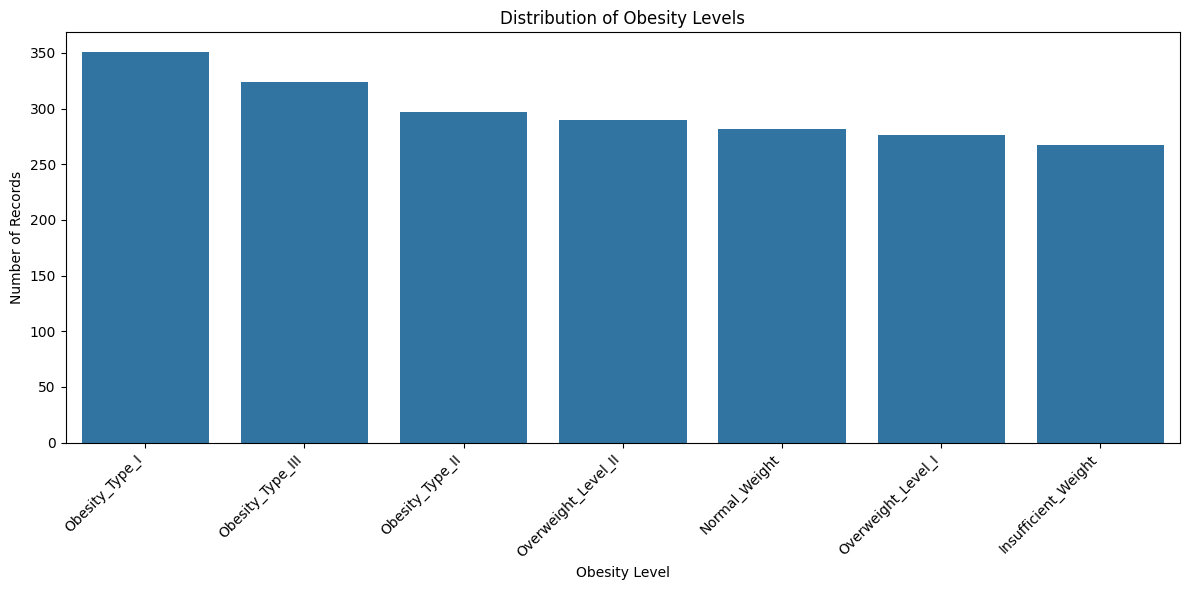

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

# Display the distribution of obesity levels
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="NObeyesdad",
    order=df["NObeyesdad"].value_counts().index
)

plt.title("Distribution of Obesity Levels")
plt.xlabel("Obesity Level")
plt.ylabel("Number of Records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



### Class Distribution Analysis

The chart shows that the seven obesity categories have relatively similar numbers of records. Obesity_Type_I has the largest number of samples, while Insufficient_Weight has the smallest. Overall, there is no severe class imbalance.

We will use stratified data splitting to preserve the proportion of each obesity category in the training, validation, and test sets. Accuracy and macro-averaged F1-score will be used to compare model performance across all seven classes.
